# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Qian 2020's malignant manifold is **non-branching**: the gastrulation (Gast) / somitogenesis (pSom) /
neural-crest (Crest) developmental signatures form one shared axis with no competing Gast-vs-pSom arms.
We (i) score + graph-smooth the three modules on the joint embedding, (ii) confirm the developmental
axis is **not** a proliferation artefact and spans the whole manifold (no scoping), (iii) test branching
**honestly** — a PPT tree is fit and its arms inspected for Gast↔pSom cross-repression — and only then
(iv) fit a fold-free principal **curve**, derive the root from developmental order, and orient the
embedding to house style.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Cells keep their **original joint-embedding coordinates** — no re-embedding (re-embedding a linear
compartment folds a strip into a U; the Kürten §4 failure mode). The three modules are scored against
the shared `union` control pool, then **graph-smoothed** (kNN-connectivity averaging, 3 passes) for
reading geography; the raw per-cell scores are retained for the deliverable UMAPs in 03.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u, s, vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv', ''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534': 'Gast', 'GSE229103': 'pSom', 'rRNAModifications': 'Crest'}
for src, lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smooth for geography (raw scores kept for deliverable UMAPs)
A = (adata.obsp['connectivities'] > 0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast', 'pSom', 'Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast', 'pSom', 'Crest']): adata.obs[lab+'_sm'] = S[:, j]
print('global module means: Gast %.3f | pSom %.3f | Crest %.3f'
      % (adata.obs.Gast.mean(), adata.obs.pSom.mean(), adata.obs.Crest.mean()))

whole malignant manifold: 6490 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.10
Gast: 77/81 genes present
pSom: 93/98 genes present
Crest: 102/104 genes present
global module means: Gast 0.044 | pSom 0.065 | Crest -0.020


### Scope decision — whole manifold vs low-cycling lobe (data-driven)
Test whether the developmental axis is confined to (or confounded by) the cycling compartment (the
Kürten lobe fork, where scoping is justified) or spans the whole manifold (the Lee case, where it is
not). Evidence below: (i) the signature geography survives in the **non-cycling cells alone**, (ii) the
Crest-high decile avoids the cycling lobe, and (iii) proliferation correlates only weakly with Gast/pSom.
→ the axis is orthogonal to the proliferation split; **keep the whole manifold**.

In [4]:
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S', 'G2/M', 'Intermediate'])
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0)
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0)
adata.obs['cyc_score'] = np.maximum(g1s, g2m)
print('overall cycling fraction: %.2f' % adata.obs['cycling'].mean())
print('\nsmoothed spatial correlations on the WHOLE manifold:')
for a, b in [('Gast_sm', 'pSom_sm'), ('Crest_sm', 'Gast_sm'), ('Crest_sm', 'pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a], adata.obs[b])[0, 1]:+.2f}')
nc = adata[~adata.obs['cycling'].values]
print(f'\nsame correlations among NON-CYCLING cells only (n={nc.shape[0]}):')
for a, b in [('Gast_sm', 'pSom_sm'), ('Crest_sm', 'Gast_sm'), ('Crest_sm', 'pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(nc.obs[a], nc.obs[b])[0, 1]:+.2f}')
print('\nsignature vs proliferation (cyc_score) — smoothed:')
for s in ['Gast', 'pSom', 'Crest']:
    print(f'  {s}_sm: r = {np.corrcoef(adata.obs[s+"_sm"], adata.obs["cyc_score"])[0, 1]:+.2f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print('\nCrest-high decile cycling fraction: %.2f (vs %.2f overall) -> Crest is late/non-proliferative'
      % (adata.obs.loc[hi.values, 'cycling'].mean(), adata.obs['cycling'].mean()))
print('-> developmental axis is orthogonal to proliferation; keep whole manifold (no scoping).')
sub = adata

overall cycling fraction: 0.23

smoothed spatial correlations on the WHOLE manifold:
  Gast_sm vs pSom_sm: r = +0.36
  Crest_sm vs Gast_sm: r = -0.28
  Crest_sm vs pSom_sm: r = -0.43

same correlations among NON-CYCLING cells only (n=4971):
  Gast_sm vs pSom_sm: r = +0.39
  Crest_sm vs Gast_sm: r = -0.34
  Crest_sm vs pSom_sm: r = -0.36

signature vs proliferation (cyc_score) — smoothed:
  Gast_sm: r = +0.11
  pSom_sm: r = +0.31
  Crest_sm: r = -0.53

Crest-high decile cycling fraction: 0.02 (vs 0.23 overall) -> Crest is late/non-proliferative
-> developmental axis is orthogonal to proliferation; keep whole manifold (no scoping).


### Honest branching test — fit a PPT tree and inspect its arms
Before committing to a curve, fit a scFates **PPT tree** and test whether its arms are a genuine
bifurcation. A real branch has one arm Gast-high/pSom-low and the other pSom-high/Gast-low (mutual
cross-repression). Here the tree's tip-branches show Gast and pSom means **positively** correlated
across arms — they co-vary, and one high-degree "tip" is simply the cycling lobe. No cross-repression
bifurcation exists → the manifold is **non-branching**; fit a curve, not a tree.

In [5]:
def graph_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B > 0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a, b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B > 0).sum(0) == 1).sum()); forks = int(((B > 0).sum(0) >= 3).sum())
    return dmin/med, tips, forks

adt = sub.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(adt, method='ppt', Nodes=30, use_rep='X_umap',
                ppt_lambda=2000, ppt_sigma=0.5, seed=SEED, plot=False)
B = np.asarray(adt.uns['graph']['B']); tps = np.where((B > 0).sum(0) == 1)[0]
D = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
hard = np.asarray(adt.obsm['X_R']).argmax(1)
seg = np.array([tps[np.argmin([D[h, tp] for tp in tps])] for h in hard])
gm, pm = [], []
print('PPT tree:', len(tps), 'tips, forks =', int(((B > 0).sum(0) >= 3).sum()))
for tp in tps:
    m = seg == tp
    gm.append(sub.obs.Gast_sm[m].mean()); pm.append(sub.obs.pSom_sm[m].mean())
    print(f'  arm->tip{tp} (n={m.sum():4d}): Gast_sm={sub.obs.Gast_sm[m].mean():+.4f} '
          f'pSom_sm={sub.obs.pSom_sm[m].mean():+.4f} Crest_sm={sub.obs.Crest_sm[m].mean():+.4f} '
          f'cycling={sub.obs.cycling[m].mean():.2f}')
print(f'corr(arm Gast means, arm pSom means) = {np.corrcoef(gm, pm)[0, 1]:+.2f}  '
      '(POSITIVE = co-vary = non-branching; NEGATIVE = cross-repression = branching)')
print('-> arms co-vary; no Gast<->pSom bifurcation. NON-BRANCHING: fit a curve.')

PPT tree: 3 tips, forks = 1
  arm->tip8 (n=2218): Gast_sm=+0.0491 pSom_sm=+0.0641 Crest_sm=-0.0106 cycling=0.11
  arm->tip22 (n=2235): Gast_sm=+0.0438 pSom_sm=+0.0730 Crest_sm=-0.0320 cycling=0.49
  arm->tip25 (n=2037): Gast_sm=+0.0321 pSom_sm=+0.0551 Crest_sm=-0.0141 cycling=0.09
corr(arm Gast means, arm pSom means) = +0.68  (POSITIVE = co-vary = non-branching; NEGATIVE = cross-repression = branching)
-> arms co-vary; no Gast<->pSom bifurcation. NON-BRANCHING: fit a curve.


### Fit the principal curve (ElPiGraph) and verify it is fold-free
`Nodes / epg_lambda / epg_mu` are chosen so the backbone is a monotone, **fold-free** line: a
node self-approach ratio > 1 (minimum distance between graph-non-adjacent nodes, in edge-length units)
and zero forks. The curve edges are rendered over the embedding later in this notebook so the topology
is judged on the drawn curve, not on a signature↔pseudotime scalar.

In [6]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=15, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = graph_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.85 (>1 = fold-free)


### Derive the root from developmental order
Developmentally, Gast/pSom mark the **origin** and Crest is **late**. The root is the curve tip where
Gast+pSom is highest and Crest lowest; pseudotime then flows toward the neural-crest terminus. (Rooting
from a proliferation state — the Kürten/Chen error — is explicitly avoided: cell cycle is checked below,
not used to root.)

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B > 0).sum(0) == 1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp] <= 3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0] + info[tp][1] - info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for s in ['Gast_sm', 'pSom_sm', 'Crest_sm', 'cyc_score']:
    rho, p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho = {rho:+.3f}  p = {p:.1e}')

tip 0: Gast=+0.0321 pSom=+0.0534 Crest=-0.0144
tip 2: Gast=+0.0454 pSom=+0.0712 Crest=-0.0351
derived root = tip 2 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho = -0.484  p = 0.0e+00
  pSom_sm: rho = -0.540  p = 0.0e+00
  Crest_sm: rho = +0.476  p = 0.0e+00
  cyc_score: rho = -0.404  p = 1.3e-253


### Reorient to house style (pseudotime left → right)
Orient with a **discrete axis/sign choice on the raw UMAP coordinates only** (no rotation — an SVD basis
can silently reflect an axis and hide a fold). Pick the raw axis most aligned with pseudotime and flip
its sign so low pseudotime is on the left.

In [8]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
rx = abs(np.corrcoef(xy[:, 0], t)[0, 1]); ry = abs(np.corrcoef(xy[:, 1], t)[0, 1])
xyr = np.column_stack([xy[:, 1], xy[:, 0]]) if ry > rx else xy.copy()
r = float(np.corrcoef(xyr[:, 0], t)[0, 1])
if r < 0:
    xyr[:, 0] = -xyr[:, 0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: corr(x_lin, pseudotime) = {r:+.2f} (low pt -> left)')

orientation: corr(x_lin, pseudotime) = +0.86 (low pt -> left)


### Save manifold + trajectory figure (deliverable, curve edges rendered)

saved manifold.h5ad + manifold.pdf (fold-free curve, 0 forks)


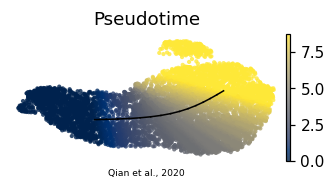

In [9]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo, xhi = np.percentile(xl[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
# curve node coords, transformed into the linear layout for the edge overlay
F = sub.uns['graph']['F'].T
Blab = np.asarray(sub.uns['graph']['B'])
Fl = np.column_stack([F[:, 1], F[:, 0]]) if ry > rx else F.copy()
if (np.corrcoef(sub.obsm['X_umap'][:, 1] if ry > rx else sub.obsm['X_umap'][:, 0], t)[0, 1]) < 0:
    Fl[:, 0] = -Fl[:, 0]
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ii, jj = np.where(np.triu(Blab > 0))
for a, b in zip(ii, jj):
    ax.plot([Fl[a, 0], Fl[b, 0]], [Fl[a, 1], Fl[b, 1]], 'k-', lw=1.0, zorder=10)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Qian et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.h5ad + manifold.pdf (fold-free curve, 0 forks)')